# Day 28 · Feeling — The day the UK hit 40 °C
### #30DayMapChallenge 2026 · ERA5-HEAT (UTCI) · Map by Emma Pidduck

The theme is a *sense* — so this is the one thing a thermometer never tells you: **what the
weather actually felt like**. On **19 July 2022** the UK passed **40 °C** for the first time
on record. Here is that afternoon drawn as the **Universal Thermal Climate Index (UTCI)** —
the "feels-like" temperature that combines air temperature, humidity, wind and radiation into
the heat load on a human body.

A deliberate change of data family for the series: not a live forecast, but **ERA5-HEAT**, the
bioclimate reanalysis from the Copernicus Climate Change Service.

## Method

- **UTCI** is the air temperature of a reference environment that would feel the same as the
  real one — it folds in humidity, 10 m wind and mean radiant temperature. ECMWF and C3S
  publish it as **ERA5-HEAT**, gridded hourly at 0.25° back to 1940.
- Pull one summer day over Europe from the **Copernicus CDS**, convert K → °C, and take the
  **mid-afternoon** hour when the heat peaked.
- Shade it with the official **UTCI heat-stress categories** (moderate 26 · strong 32 ·
  very strong 38 · extreme 46 °C) drawn as labelled contour lines over a warm fill.

Why reanalysis, not a forecast? Because the point is a *known* event — the real index on the
real day — and UTCI isn't in ECMWF's forecast open data (its inputs are, but the certified
product lives on the CDS). This is the series stretching to a second dataset on purpose.

## Licence & attribution

**ERA5-HEAT** (UTCI & mean radiant temperature) is produced by the **Copernicus Climate
Change Service (C3S)** and distributed via the Climate Data Store under the
[Copernicus licence](https://cds.climate.copernicus.eu/).

> Contains modified Copernicus Climate Change Service information 2022. Neither the European
> Commission nor ECMWF is responsible for any use of the Copernicus information.

Dataset: [derived-utci-historical](https://cds.climate.copernicus.eu/datasets/derived-utci-historical).
Reference: Di Napoli, Barnard, Prudhomme, Cloke & Pappenberger (2021), *ERA5-HEAT: A global
gridded historical dataset of human thermal comfort indices*, Geoscience Data Journal.

## Tools

| Tool | Role |
|---|---|
| [`cdsapi`](https://github.com/ecmwf/cdsapi) | retrieve ERA5-HEAT from the Copernicus CDS |
| `xarray` · `numpy` | read the NetCDF, pick the hour, K → °C |
| `cartopy` · `matplotlib` | projection, coastlines, the heat render |

Unlike the forecast open-data days, this needs a **free CDS account**: put your key in
`~/.cdsapirc` and **accept the dataset licence once** on the dataset page, or the request
returns a licence error. The request has no `time`/`format` keys — it returns the whole day —
and `version` is required.

In [1]:
# Run once if needed (uncomment):
#!pip install cdsapi xarray netcdf4 cartopy matplotlib

In [2]:
import os, zipfile, shutil
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
from matplotlib.colors import to_rgba, LinearSegmentedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#222222", "#6b6b6b"

### Configuration

A **fixed historical day** (unlike the live-forecast days): 19 July 2022, the UK 40 °C event.
Change `DAY`/`HOUR` for another heatwave — e.g. the July 2023 Mediterranean "Cerberus" peak.

In [3]:
YEAR, MONTH, DAY, HOUR = "2022", "07", "19", 14      # 14:00 UTC — mid-afternoon
AREA = [72, -25, 34, 45]                             # N, W, S, E — Europe + near Atlantic
NC   = f"data/day28_utci_{YEAR}{MONTH}{DAY}.nc"
CATS = [9, 26, 32, 38, 46]                           # UTCI heat-stress thresholds (°C)
CAT_LABELS = {26: "moderate", 32: "strong", 38: "very strong", 46: "extreme"}

## Retrieve from the CDS

`version` is mandatory; there is no `time` or `format` key (a request returns the full day as
a zipped NetCDF), so we unzip the single `.nc` out.

In [4]:
os.makedirs("data", exist_ok=True)
if not os.path.exists(NC):
    import cdsapi
    raw = NC.replace(".nc", ".download")
    cdsapi.Client().retrieve("derived-utci-historical", {
        "variable": "universal_thermal_climate_index",
        "version": "1_1", "product_type": "consolidated_dataset",
        "year": YEAR, "month": MONTH, "day": DAY, "area": AREA,
    }, raw)
    if open(raw, "rb").read(2) == b"PK":             # zipped NetCDF -> extract the .nc
        with zipfile.ZipFile(raw) as z:
            nc = [n for n in z.namelist() if n.endswith(".nc")][0]
            z.extract(nc, "data"); shutil.move(os.path.join("data", nc), NC)
        os.remove(raw)
    else:
        shutil.move(raw, NC)

## Read & pick the hour

In [5]:
d = xr.open_dataset(NC)["utci"] - 273.15            # K -> °C
u = d.isel(time=HOUR)
lon = u["lon"].values; lat = u["lat"].values
when = str(d.time.values[HOUR])[:16].replace("T", " ") + " UTC"
print(f"{when}   UTCI {float(u.min()):.0f} to {float(u.max()):.0f} °C   grid {u.shape}")

2022-07-19 14:00 UTC   UTCI -10 to 52 °C   grid (153, 281)


### Colour — warm, and colourblind-safe

A pale-cream → deep-brick-red ramp: hotter is deeper, nothing goes to black. It is
**monotonic in luminance**, so it reads correctly for every form of colour-vision deficiency
and in greyscale — verified below.

In [6]:
CMAP = LinearSegmentedColormap.from_list("heat",
    ["#fff7ec", "#fee8c8", "#fdd49e", "#fdbb84", "#fc8d59", "#ef6548", "#d7301f", "#990000"])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) <= 1e-3).all() or (np.diff(lum) >= -1e-3).all()   # monotonic either way
print("heat ramp luminance-monotonic:", bool(mono), f"({lum[0]:.2f} -> {lum[-1]:.2f})")

heat ramp luminance-monotonic: True (0.97 -> 0.13)


## Render

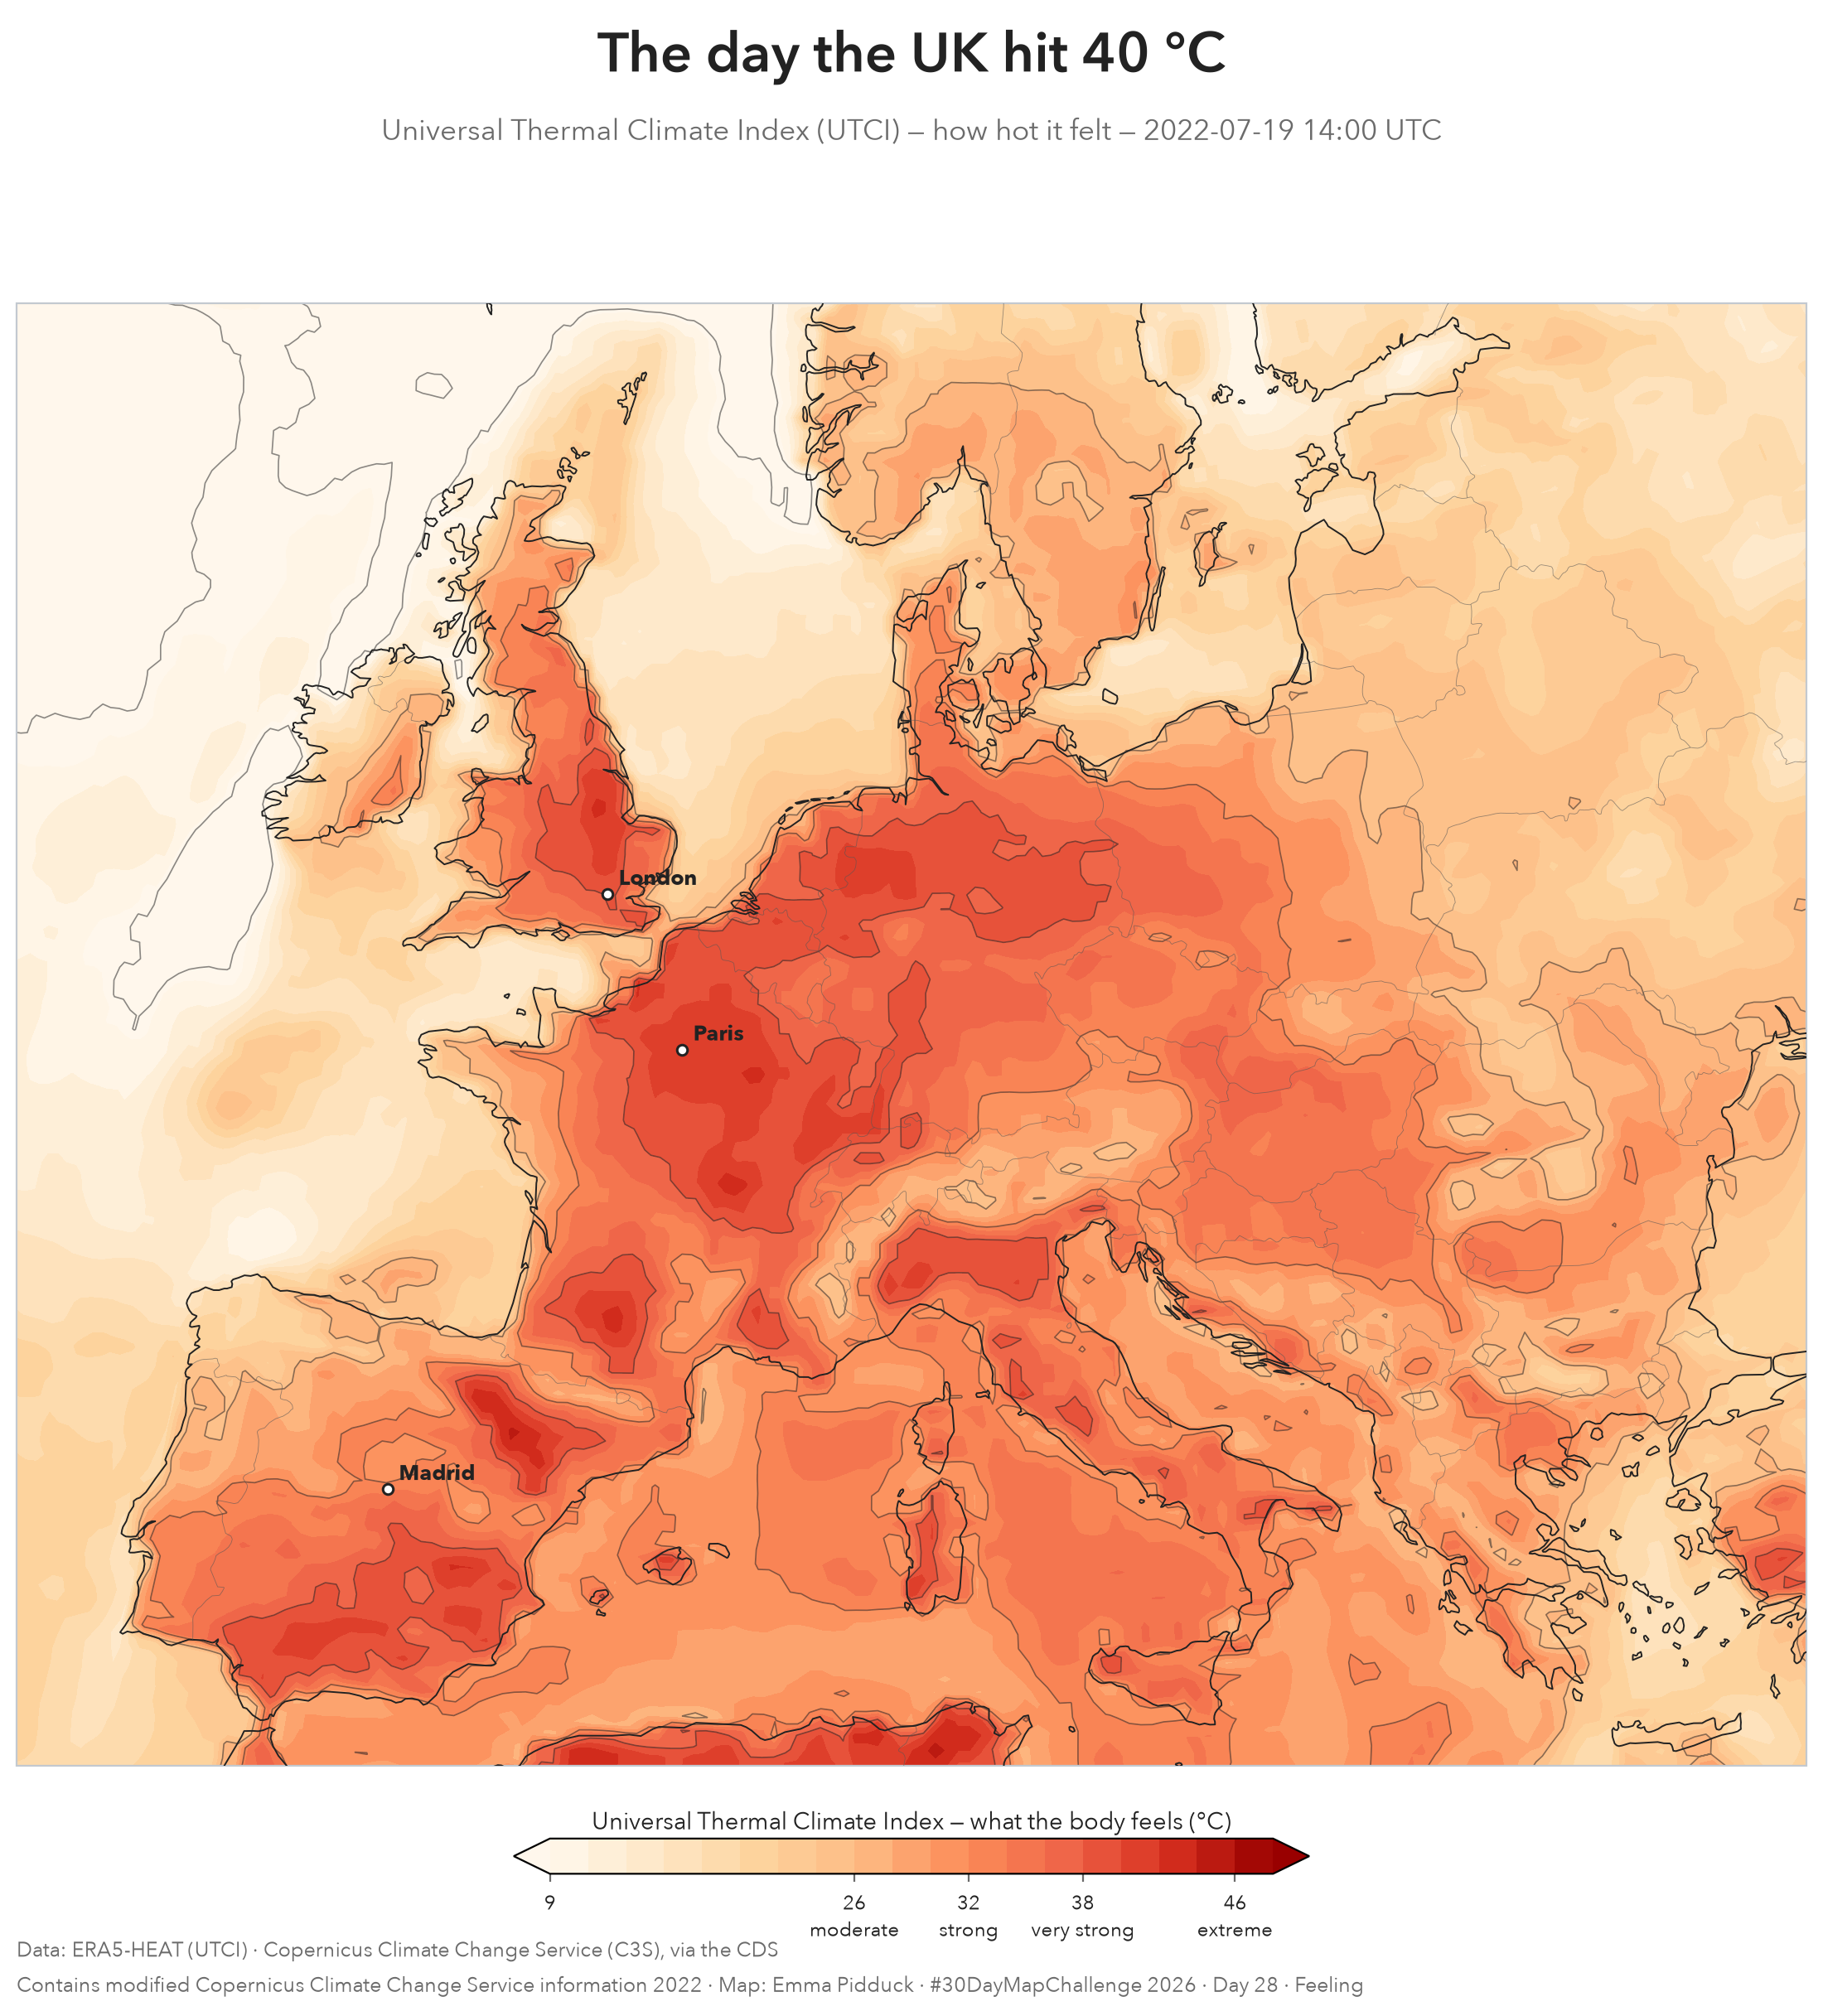

In [7]:
proj = ccrs.LambertConformal(central_longitude=8, central_latitude=50, standard_parallels=(40, 60))
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(12, 12.5), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.05, 0.10, 0.90, 0.78], projection=proj)
ax.set_extent([-11, 28, 36, 61], crs=ccrs.PlateCarree()); ax.set_facecolor("#eef2f5")

levels = np.arange(10, 48.1, 2)
cf = ax.contourf(lon, lat, u.values, levels=levels, cmap=CMAP, extend="both", zorder=0, **tp)
ax.contour(lon, lat, u.values, levels=CATS, colors="#2b2b2b", linewidths=0.6, alpha=0.55, zorder=2, **tp)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.7, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#555", linewidth=0.3, alpha=0.6, zorder=3)
try: ax.spines["geo"].set_edgecolor("#c3c9d0"); ax.spines["geo"].set_linewidth(0.8)
except Exception: pass

for name, la, lo in [("London", 51.51, -0.13), ("Paris", 48.85, 2.35), ("Madrid", 40.42, -3.70)]:
    ax.plot(lo, la, "o", ms=4.5, mfc="#fff", mec=INK, mew=1.1, transform=ccrs.PlateCarree(), zorder=5)
    ax.annotate(name, (lo, la), xytext=(5, 4), textcoords="offset points",
                transform=ccrs.PlateCarree(), fontsize=9.5, fontweight="bold", color=INK, zorder=5)

cax = fig.add_axes([0.30, 0.085, 0.40, 0.017])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="both")
cb.set_label("Universal Thermal Climate Index — what the body feels (°C)", color=INK, fontsize=10.5)
cb.ax.xaxis.set_label_position("top"); cb.set_ticks(CATS)
cb.ax.set_xticklabels([f"{c}\n{CAT_LABELS.get(c,'')}" for c in CATS], fontsize=8.5)
cb.ax.xaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)

fig.text(0.5, 0.955, "The day the UK hit 40 °C", ha="center", color=INK, fontsize=24, fontfamily=["Avenir Next Demi Bold", "Arial", "DejaVu Sans"])
fig.text(0.5, 0.922, f"Universal Thermal Climate Index (UTCI) — how hot it felt — {when}",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.05, 0.045, "Data: ERA5-HEAT (UTCI) · Copernicus Climate Change Service (C3S), via the CDS",
         color=MUT, fontsize=9)
fig.text(0.05, 0.028, "Contains modified Copernicus Climate Change Service information 2022 · Map: Emma Pidduck · #30DayMapChallenge 2026 · Day 28 · Feeling",
         color=MUT, fontsize=9)
fig.savefig("day28_feeling_utci.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

The deep-red core sits over northern France, Belgium and the Low Countries — UTCI in the
**very strong / extreme** heat-stress bands — with the plume reaching across the Channel on the
day the UK first recorded 40 °C — 40.3 °C at Coningsby, Lincolnshire, in England, ~15 UTC.
Southern Iberia, long used to
heat, shows the same categories; the contrast is in what each population is adapted to.

*A second data family for the series: ERA5-HEAT reanalysis via the Copernicus CDS, alongside
the ECMWF IFS forecasts and MeteoSwiss ICON-CH1. Day 2 Lines · Day 6 Vintage · Day 20 Hexagons
· Day 22 Projections.*
